# Threshold curves — `biased_bell_v2`

Per-direction logical-error-rate vs `p` curves for the Bell-mediated noise model.
Each direction is either:

- **bias** `β` → `p_bell_z = β · p` (sweep `p`), or
- **fixed `p_bell_z`** → `p_bell_z` held constant while `p` sweeps.

Reads CSVs written by `tools/decode.py` (preamble `threshold_bell`).
Mirrors `threshold_comparison.ipynb` and `threshold_3d_surface.ipynb` in style.

In [22]:
import sys
import ast
import glob
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from threshold_fit import locate_threshold, fit_threshold

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [23]:
CSV_GLOB = '../out/collection/threshold_bell,*.csv'

files = sorted(glob.glob(CSV_GLOB))
if not files:
    raise FileNotFoundError(f'No files matched: {CSV_GLOB}')
print(f'Loading {len(files)} file(s):')
for f in files:
    print(f'  {f}')

df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

# Merge repeated runs by strong_id (same circuit + decoder).
df = df.groupby('strong_id').agg({
    'shots': 'sum',
    'errors': 'sum',
    'discards': 'sum',
    'seconds': 'sum',
    'decoder': 'first',
    'json_metadata': 'first',
}).reset_index()

# Pull metadata columns we'll group/plot on.
def _parse(meta):
    return ast.literal_eval(meta) if isinstance(meta, str) else dict(meta)

meta = df['json_metadata'].apply(_parse)
for col in [
    'p', 'p_bell_z', 'direction_kind', 'direction_value',
    'bias', 'p_bell_z_fixed', 'expected_distance', 'rounds', 'k',
    'noise_model',
]:
    df[col] = meta.apply(lambda m, c=col: m.get(c))

df = df[df['noise_model'] == 'biased_bell_v2'].reset_index(drop=True)

# A single string label per direction, used for grouping + titles + filenames.
def _direction_label(row):
    if row['direction_kind'] == 'bias':
        b = row['direction_value']
        return f'bias={int(b) if b == int(b) else b:g}'
    return f'pbz={row["direction_value"]:.4g}'

df['direction'] = df.apply(_direction_label, axis=1)
print(f'{len(df)} rows, {df["direction"].nunique()} directions, '
      f'distances={sorted(df["expected_distance"].dropna().unique())}')

Loading 1 file(s):
  ../out/collection/threshold_bell,2026-06-23.csv
672 rows, 8 directions, distances=[np.int64(3), np.int64(5), np.int64(7)]


In [24]:
# Fit a threshold per direction. Same pipeline as threshold_3d_surface.ipynb:
# convert per-circuit logical error rate to a per-d-rounds, per-observable
# rate, then run the locate -> quadratic-FSS fit from src/threshold_fit.py.

N_PER_SIDE = 2          # 5-point window around p_init
LOGICAL_CUTOFF = 0.3    # drop saturated points

fit_rows = []
for direction_name, grp in df.groupby('direction'):
    p_arr = grp['p'].to_numpy(dtype=float)
    d_arr = grp['expected_distance'].to_numpy(dtype=float)
    rounds_arr = grp['rounds'].to_numpy(dtype=float)
    k_arr = grp['k'].to_numpy(dtype=float)
    shots_arr = grp['shots'].to_numpy(dtype=float)
    errors_arr = grp['errors'].to_numpy(dtype=float)

    valid = (
        (shots_arr > 0)
        & (errors_arr > 0)
        & (errors_arr < shots_arr * LOGICAL_CUTOFF)
    )
    pL_total = np.where(valid, errors_arr / np.maximum(shots_arr, 1), np.nan)
    sigma_total = np.where(
        valid,
        np.sqrt(
            np.clip(pL_total * (1 - pL_total), 0, None)
            / np.maximum(shots_arr, 1)
        ),
        np.nan,
    )

    # Per-round, per-observable single-event rate.
    scale = d_arr / (rounds_arr * np.maximum(k_arr, 1))
    pL = 1 - (1 - pL_total) ** scale
    sigma = sigma_total * scale * (1 - pL_total) ** (scale - 1)

    p_init = locate_threshold(p_arr, d_arr, pL)
    if p_init is None:
        continue
    fit = fit_threshold(
        p_arr, d_arr, pL,
        sigma=sigma,
        p_init=p_init,
        n_per_side=N_PER_SIDE,
    )
    if fit is None:
        continue

    direction_kind = grp['direction_kind'].iloc[0]
    bias = grp['bias'].iloc[0]
    p_bell_z_fixed = grp['p_bell_z_fixed'].iloc[0]
    fit_rows.append({
        'direction': direction_name,
        'direction_kind': direction_kind,
        'bias': bias,
        'p_bell_z_fixed': p_bell_z_fixed,
        'p_th': fit.p_th,
        'p_th_err': fit.p_th_err,
        'mu': fit.mu,
        'mu_err': fit.mu_err,
        'p_init': fit.p_init,
        'n_points': fit.n_points,
    })

fits_df = pd.DataFrame(fit_rows)

# Sort: biases first (numeric), then fixed pbz (numeric).
fits_df['_sort'] = (
    fits_df['direction_kind'].map({'bias': 0, 'pbz': 1}) * 1e9
    + fits_df['direction_value' if False else 'bias'].fillna(0).astype(float)
    + fits_df['p_bell_z_fixed'].fillna(0).astype(float) * 1e3
)
fits_df = fits_df.sort_values('_sort').drop(columns='_sort').reset_index(drop=True)
fits_df

,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,bias=0,bias,0.0,NaN,0.002423,0.000022,0.930004,0.046166,0.002512,15
1,bias=1,bias,1.0,NaN,0.002036,0.000018,0.841453,0.035499,0.001995,15
2,bias=3,bias,3.0,NaN,0.001488,0.000013,0.942626,0.037977,0.001585,14
3,bias=10,bias,10.0,NaN,0.000799,0.000007,0.866917,0.029981,0.000858,14
4,bias=30,bias,30.0,NaN,0.000349,0.000004,0.790182,0.025319,0.000341,13
5,bias=100,bias,100.0,NaN,0.000117,0.000002,0.931060,0.055457,0.000136,8
6,pbz=0.001,pbz,NaN,0.001,0.002216,0.000019,0.928855,0.045378,0.002154,15
7,pbz=0.01,pbz,NaN,0.010,0.000527,0.000017,1.035512,0.069778,0.000631,15


p_init  = 0.0003415
p_th    = 0.0003491 +/- 3.7e-06
mu      = 0.79 +/- 0.025
window  = (0.00018478497974222906, 0.00025118864315095795, 0.0003414548873833601, 0.00046415888336127773, 0.000630957344480193)
n_points (in fit) = 13


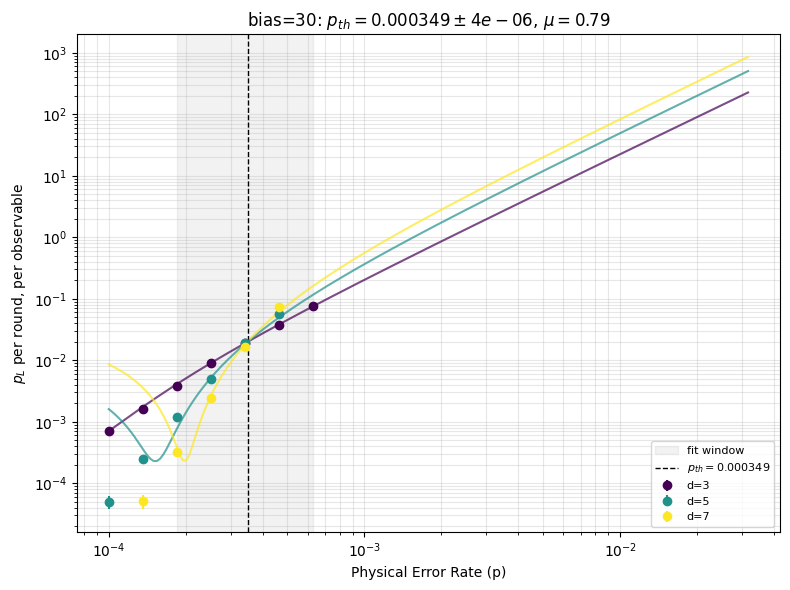

In [25]:
# Diagnostic plot for a single direction: re-run the fit, then plot
# - data points (per distance, with binomial errorbars)
# - the fitted FSS curves
# - the fit window (shaded) and p_th (vertical line)
#
# Useful when a fit looks off (e.g. bias=30) and you want to see whether
# it's the window, the data, or the model.

DIAG_DIRECTION = 'bias=30'   # change to inspect another direction
DIAG_N_PER_SIDE = N_PER_SIDE
DIAG_LOGICAL_CUTOFF = LOGICAL_CUTOFF

grp = df[df['direction'] == DIAG_DIRECTION]
if grp.empty:
    raise ValueError(
        f'No rows for direction={DIAG_DIRECTION!r}. '
        f'Available: {sorted(df["direction"].unique())}'
    )

p_arr = grp['p'].to_numpy(dtype=float)
d_arr = grp['expected_distance'].to_numpy(dtype=float)
rounds_arr = grp['rounds'].to_numpy(dtype=float)
k_arr = grp['k'].to_numpy(dtype=float)
shots_arr = grp['shots'].to_numpy(dtype=float)
errors_arr = grp['errors'].to_numpy(dtype=float)

valid = (
    (shots_arr > 0)
    & (errors_arr > 0)
    & (errors_arr < shots_arr * DIAG_LOGICAL_CUTOFF)
)
pL_total = np.where(valid, errors_arr / np.maximum(shots_arr, 1), np.nan)
sigma_total = np.where(
    valid,
    np.sqrt(np.clip(pL_total * (1 - pL_total), 0, None) / np.maximum(shots_arr, 1)),
    np.nan,
)
scale = d_arr / (rounds_arr * np.maximum(k_arr, 1))
pL = 1 - (1 - pL_total) ** scale
sigma = sigma_total * scale * (1 - pL_total) ** (scale - 1)

p_init = locate_threshold(p_arr, d_arr, pL)
fit = fit_threshold(p_arr, d_arr, pL, sigma=sigma, p_init=p_init, n_per_side=DIAG_N_PER_SIDE)

print(f'p_init  = {p_init:.4g}')
print(f'p_th    = {fit.p_th:.4g} +/- {fit.p_th_err:.2g}')
print(f'mu      = {fit.mu:.3g} +/- {fit.mu_err:.2g}')
print(f'window  = {fit.p_window}')
print(f'n_points (in fit) = {fit.n_points}')

fig, ax = plt.subplots(figsize=(8, 6))

distances = sorted(np.unique(d_arr[np.isfinite(d_arr)]))
cmap = plt.get_cmap('viridis')
colors = {d: cmap(i / max(1, len(distances) - 1)) for i, d in enumerate(distances)}

# Smooth p grid for the fit overlay.
finite_p = p_arr[(p_arr > 0) & np.isfinite(p_arr)]
p_smooth = np.geomspace(finite_p.min(), finite_p.max(), 200)

for d in distances:
    mask = (d_arr == d) & np.isfinite(pL) & (pL > 0)
    ax.errorbar(
        p_arr[mask], pL[mask], yerr=sigma[mask],
        fmt='o', color=colors[d], label=f'd={int(d)}',
    )
    ax.plot(
        p_smooth, fit.predict(p_smooth, np.full_like(p_smooth, d)),
        color=colors[d], linestyle='-', alpha=0.7,
    )

# Shade the fit window.
w_lo, w_hi = min(fit.p_window), max(fit.p_window)
ax.axvspan(w_lo, w_hi, alpha=0.1, color='gray', label='fit window')
ax.axvline(fit.p_th, color='k', linestyle='--', linewidth=1,
           label=f'$p_{{th}}={fit.p_th:.3g}$')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Physical Error Rate (p)')
ax.set_ylabel(r'$p_L$ per round, per observable')
ax.set_title(
    f"{DIAG_DIRECTION}: $p_{{th}}={fit.p_th:.3g} \\pm {fit.p_th_err:.1g}$, "
    f"$\\mu={fit.mu:.2g}$"
)
ax.grid(True, alpha=0.3, which='both')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

<>:71: SyntaxWarning: invalid escape sequence '\p'
<>:71: SyntaxWarning: invalid escape sequence '\p'
/var/folders/8g/7b0sw56542b6xspbj28nxd0h0000gq/T/ipykernel_81988/1897177877.py:71: SyntaxWarning: invalid escape sequence '\p'
  f"$p_{{th}}={fit['p_th']:.3g} \pm {fit['p_th_err']:.1g}$"
/var/folders/8g/7b0sw56542b6xspbj28nxd0h0000gq/T/ipykernel_81988/1897177877.py:79: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


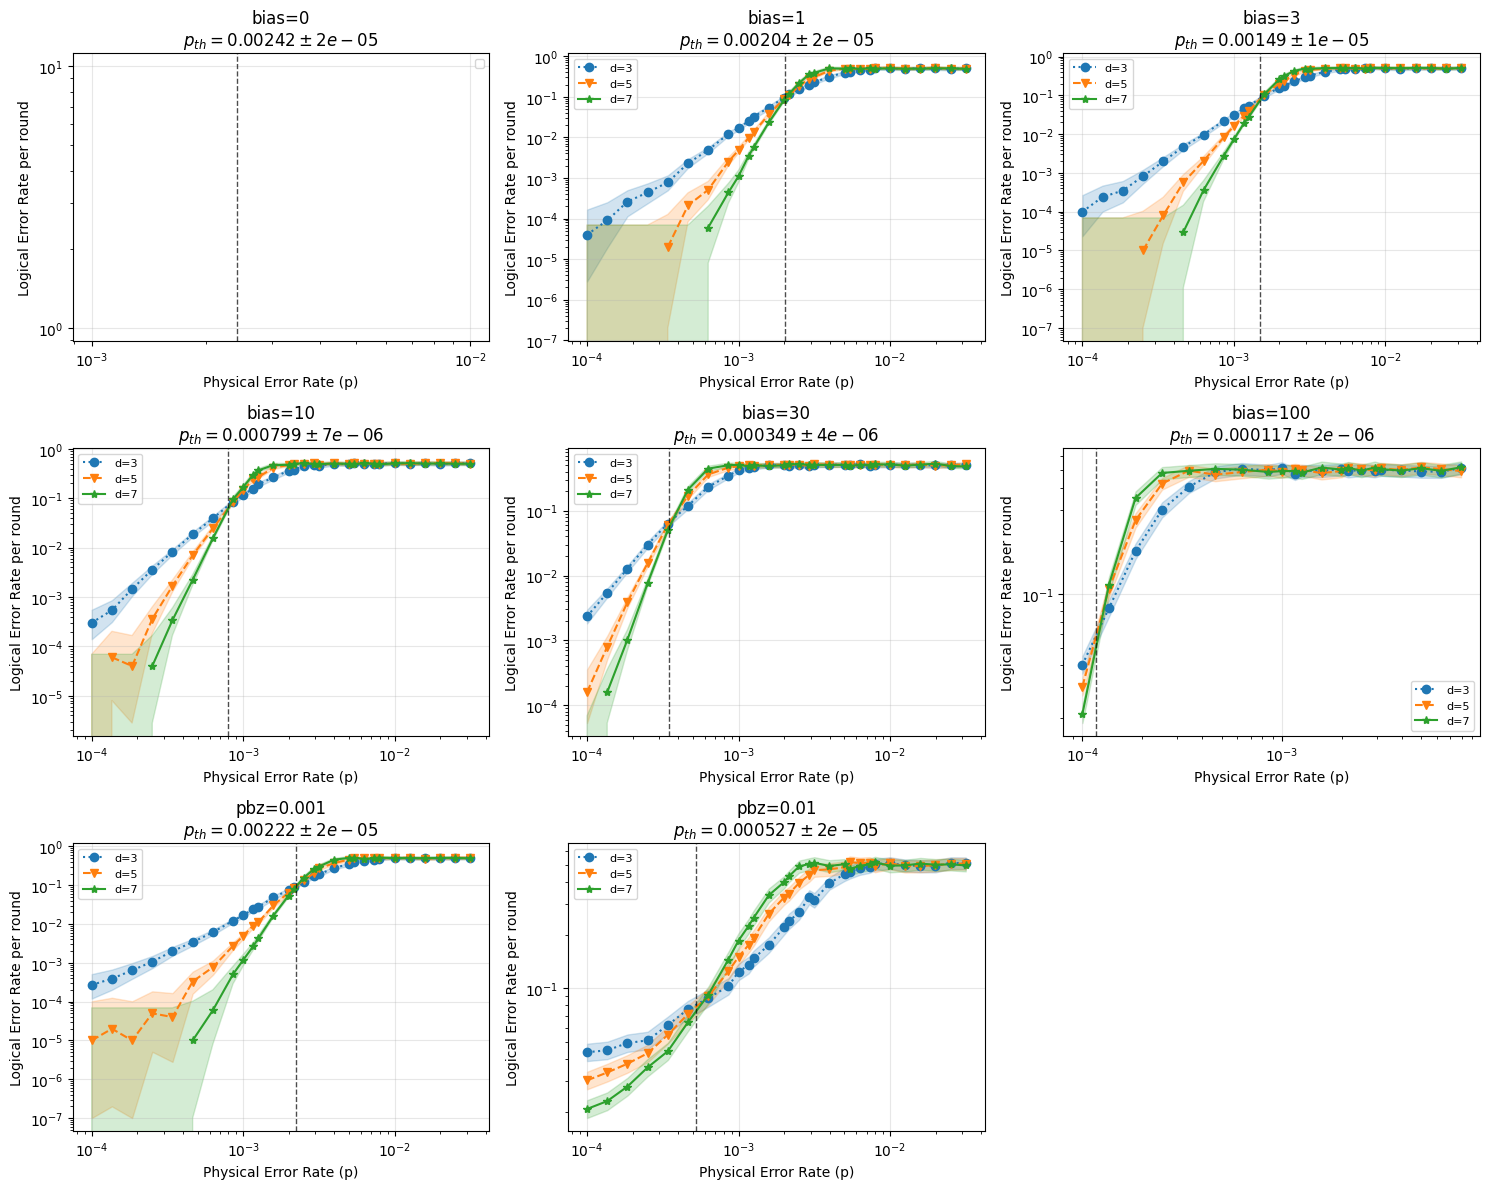

In [26]:
# Per-direction logical-error-rate curves, with the fitted threshold drawn
# as a vertical dashed line. Same plotting pattern as threshold_3d_surface.ipynb.

import sinter
from types import SimpleNamespace

LINESTYLES = {2: ':', 3: ':', 4: '--', 5: '--', 6: '-', 7: '-'}

def _plot_args_func(index, group_key, group_stats):
    m = group_stats[0].json_metadata
    return {'linestyle': LINESTYLES.get(m.get('expected_distance'), '-')}

# Build sinter-like stat objects for the helper.
def _row_to_stat(row):
    meta = row['json_metadata']
    if isinstance(meta, str):
        meta = ast.literal_eval(meta)
    return SimpleNamespace(
        json_metadata=meta,
        shots=int(row['shots']),
        errors=int(row['errors']),
        discards=int(row['discards']),
        seconds=float(row['seconds']),
        decoder=row['decoder'],
        strong_id=row['strong_id'],
    )

stats_all = [_row_to_stat(r) for _, r in df.iterrows()]

# Stable ordering: biases ascending, then fixed-pbz ascending.
def _direction_sort_key(d):
    sub = df[df['direction'] == d].iloc[0]
    if sub['direction_kind'] == 'bias':
        return (0, float(sub['bias']))
    return (1, float(sub['p_bell_z_fixed']))

direction_names = sorted(df['direction'].unique(), key=_direction_sort_key)

n = len(direction_names)
ncols = 3
nrows = (n + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows), squeeze=False)

fits_lookup = fits_df.set_index('direction').to_dict('index') if not fits_df.empty else {}

for idx, direction_name in enumerate(direction_names):
    ax = axes[idx // ncols][idx % ncols]
    direction_stats = [s for s in stats_all if s.json_metadata.get('direction_kind') == ('bias' if direction_name.startswith('bias=') else 'pbz')]
    # Filter to this exact direction.
    if direction_name.startswith('bias='):
        bval = float(direction_name.split('=', 1)[1])
        direction_stats = [s for s in direction_stats if float(s.json_metadata.get('bias') or -1) == bval]
    else:
        zval = float(direction_name.split('=', 1)[1])
        direction_stats = [s for s in direction_stats if abs(float(s.json_metadata.get('p_bell_z_fixed') or -1) - zval) < 1e-12]

    sinter.plot_error_rate(
        ax=ax,
        stats=direction_stats,
        x_func=lambda stat: stat.json_metadata['p'],
        group_func=lambda stat: f'd={stat.json_metadata["expected_distance"]}',
        plot_args_func=_plot_args_func,
        failure_values_func=lambda stat: stat.json_metadata.get('k', 1),
    )

    fit = fits_lookup.get(direction_name)
    if fit is not None and np.isfinite(fit['p_th']):
        ax.axvline(fit['p_th'], color='k', linestyle='--', linewidth=1, alpha=0.7)
        ax.set_title(
            f"{direction_name}\n"
            f"$p_{{th}}={fit['p_th']:.3g} \pm {fit['p_th_err']:.1g}$"
        )
    else:
        ax.set_title(direction_name)

    ax.loglog()
    ax.set_xlabel('Physical Error Rate (p)')
    ax.set_ylabel('Logical Error Rate per round')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

for idx in range(len(direction_names), nrows * ncols):
    axes[idx // ncols][idx % ncols].axis('off')

fig.tight_layout()
plt.show()

In [27]:
# Persist fits for the threshold-vs-bias notebook.
out_path = Path('../out/collection/threshold_bell_fits.csv')
fits_df.to_csv(out_path, index=False)
print(f'Saved fits -> {out_path}')
fits_df

Saved fits -> ../out/collection/threshold_bell_fits.csv


,direction,direction_kind,bias,p_bell_z_fixed,p_th,p_th_err,mu,mu_err,p_init,n_points
0,bias=0,bias,0.0,NaN,0.002423,0.000022,0.930004,0.046166,0.002512,15
1,bias=1,bias,1.0,NaN,0.002036,0.000018,0.841453,0.035499,0.001995,15
2,bias=3,bias,3.0,NaN,0.001488,0.000013,0.942626,0.037977,0.001585,14
3,bias=10,bias,10.0,NaN,0.000799,0.000007,0.866917,0.029981,0.000858,14
4,bias=30,bias,30.0,NaN,0.000349,0.000004,0.790182,0.025319,0.000341,13
5,bias=100,bias,100.0,NaN,0.000117,0.000002,0.931060,0.055457,0.000136,8
6,pbz=0.001,pbz,NaN,0.001,0.002216,0.000019,0.928855,0.045378,0.002154,15
7,pbz=0.01,pbz,NaN,0.010,0.000527,0.000017,1.035512,0.069778,0.000631,15
